# Object detection — quickstart

**Object detection** finds every object in an image and returns, for each, a **box** and a **class** (plus a confidence score). Unlike classification, an image can hold zero, one or many objects. The demo detects circles, squares and triangles.

This notebook runs the **whole pipeline in about ten cells**. The other notebooks slow down and explain each step.

**Data → Train → Evaluate → Predict** &nbsp;·&nbsp; runs on CPU in about 5 minutes with the `quick` preset.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/detection/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("detection", cfg)
print("task:", "detection", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: detection | data: data/demo/detection | outputs: outputs/detection_quick


## 1 · The data
A few examples, with their labels:

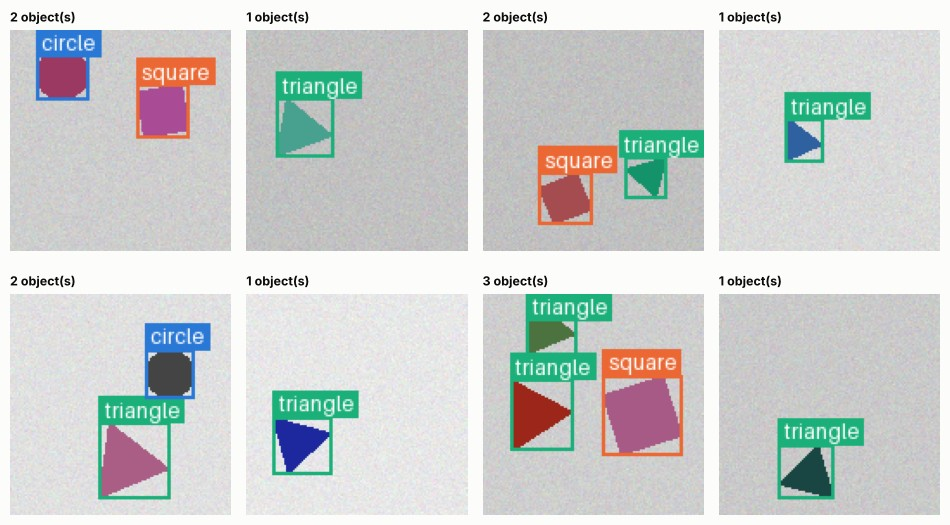

In [3]:
from PIL import Image
from cvkit.coco import load_coco
from cvkit.viz import draw_boxes

coco = load_coco(cfg["data"]["root"], cfg["data"].get("annotations", "annotations.json"), cfg["data"].get("images_dir", "images"))
classes, items = coco["classes"], coco["images"]
from cvkit.viz import image_grid

shown = [draw_boxes(Image.open(im["path"]), [a["bbox"] for a in im["annotations"]], [a["label"] for a in im["annotations"]], classes=classes)
         for im in items[:8]]
_ = image_grid(shown, [f"{len(im['annotations'])} object(s)" for im in items[:8]], cols=4, cell=2.4)

## 2 · Train
`train(cfg)` is the same function the command line calls: `python -m cvkit detection train --quick`. It prints one line per epoch and saves the best model.

In [4]:
from tasks.detection.train import train

result = train(cfg)

arch: fasterrcnn_resnet18_fpn | classes (3): ['circle', 'square', 'triangle']


device: cpu | parameters: 28,293,731 total, 28,293,731 trainable (100.0%)


epoch   1/15 | train_loss 4.6367 | val map=0.004 map50=0.014 map75=0.000 | 19.0s  <- best


epoch   2/15 | train_loss 1.2690 | val map=0.172 map50=0.471 map75=0.037 | 19.0s  <- best


epoch   3/15 | train_loss 1.0232 | val map=0.258 map50=0.570 map75=0.244 | 20.1s  <- best


...

epoch  11/15 | train_loss 0.3367 | val map=0.734 map50=1.000 map75=0.904 | 22.1s  <- best


epoch  12/15 | train_loss 0.2773 | val map=0.822 map50=0.997 map75=0.982 | 21.5s  <- best


epoch  13/15 | train_loss 0.2448 | val map=0.836 map50=1.000 map75=1.000 | 23.4s  <- best


epoch  14/15 | train_loss 0.2228 | val map=0.849 map50=0.999 map75=0.999 | 22.1s  <- best


epoch  15/15 | train_loss 0.1809 | val map=0.872 map50=0.999 map75=0.999 | 22.3s  <- best
best val map = 0.8724 (epoch 15) -> outputs/detection_quick/checkpoints/best.pt


## 3 · Evaluate on the held-out test split
Images the model never trained on, and never used to pick its best epoch.

In [5]:
from tasks.detection.evaluate import evaluate

metrics = evaluate(cfg)

mAP@[.5:.95] 0.906 | mAP@.5 1.000 | mAP@.75 1.000 (36 test images)
at score >= 0.5: precision 0.908 | recall 1.000 (TP 79, FP 8, FN 0)
  AP@.5 circle           1.000
  AP@.5 square           1.000
  AP@.5 triangle         1.000
reports -> outputs/detection_quick/reports


ap_per_class.png


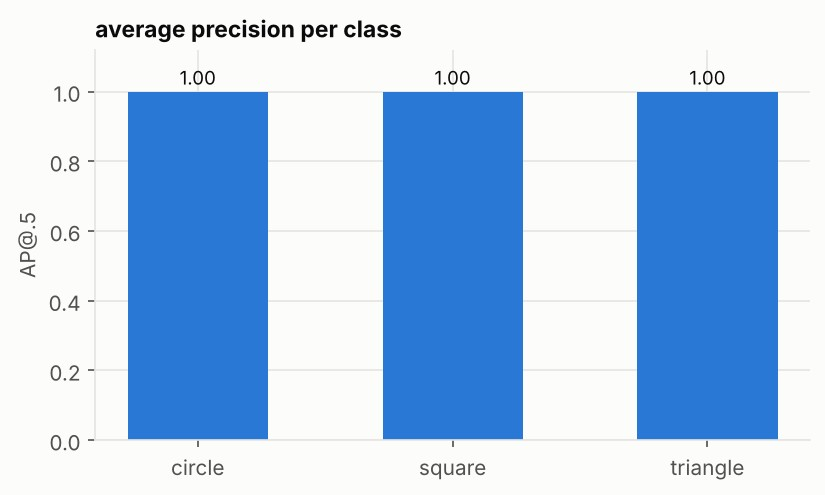

predictions.png


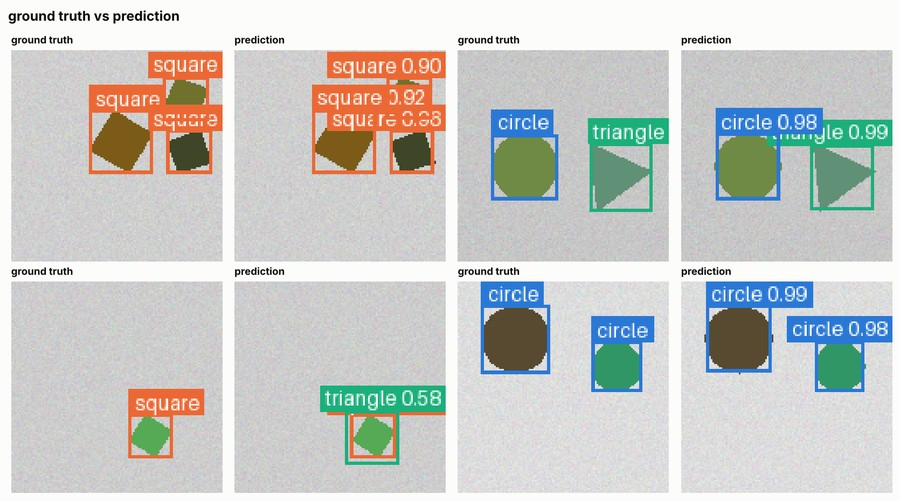

worst_images.png


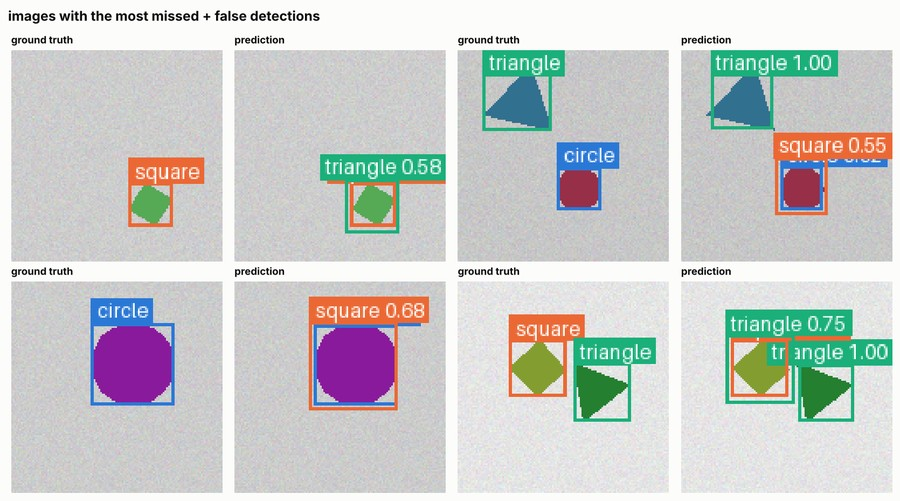

In [6]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['ap_per_class.png', 'predictions.png', 'worst_images.png']:
    print(name)
    show_image(reports / name)

**Reading it:** `predictions.png` puts the ground truth next to the model's boxes. `ap_per_class.png` shows how well each class is detected. `worst_images.png` shows the images with the most missed and false detections — start error analysis there.

## 4 · Predict
`Predictor.predict` returns a list of detections (label, confidence, box); `visualize` draws them:

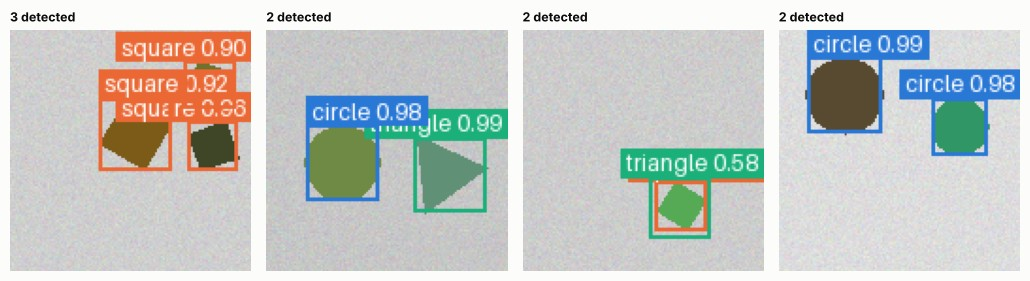

In [7]:
from cvkit.viz import image_grid
from tasks.detection.predict import Predictor
from tasks.detection.data import test_image_paths

predictor = Predictor.from_config(cfg)
paths = test_image_paths(cfg, 4)
dets = [predictor.predict(p) for p in paths]
_ = image_grid([predictor.visualize(p, d) for p, d in zip(paths, dets)], [f"{len(d)} detected" for d in dets], cols=4, cell=2.6)

## What next?
* **[01_data](01_data.ipynb)** — look at the data and augmentation properly
* **[02_train_and_evaluate](02_train_and_evaluate.ipynb)** — learning curves, how to read the metrics, experiments
* **[03_predict_and_deploy](03_predict_and_deploy.ipynb)** — your own images, the demo app, deployment
* Read the task's [README](../README.md) · use your own data: [data formats](../../../docs/data-formats.md)